# Assignment 3 — Module 3: Evolutionary and Swarm Optimization


## Practical 7: Convergence Analysis of a Genetic Algorithm

### Aim
To study the convergence of a Genetic Algorithm by observing changes in fitness values over multiple generations using Python.

### Theory
Because a GA is stochastic, a single run can be misleading. **Convergence analysis** therefore repeats the GA with several random seeds and studies the mean and spread of the best fitness per generation. A useful convergence curve is one that decreases quickly at first and then flattens as the population settles near an optimum.

### Multi-run GA with tracking

In [1]:
import numpy as np
import matplotlib.pyplot as plt

DIM, LOW, HIGH = 5, -5.12, 5.12

def sphere(x): return np.sum(x**2)
def fitness(x): return 1.0 / (1.0 + sphere(x))

def run_ga(seed, pop_size=50, generations=100, pm=0.1, sigma=0.3):
    rng = np.random.default_rng(seed)
    pop = rng.uniform(LOW, HIGH, size=(pop_size, DIM))
    best_hist = []

    for _ in range(generations):
        fits = np.array([fitness(i) for i in pop])
        best_hist.append(sphere(pop[np.argmax(fits)]))
        new_pop = [pop[np.argmax(fits)].copy()]
        while len(new_pop) < pop_size:
            # tournament selection
            def pick():
                idx = rng.choice(pop_size, 3, replace=False)
                return pop[idx[np.argmax(fits[idx])]]
            p1, p2 = pick(), pick()
            a = rng.random()
            for c in (a*p1 + (1-a)*p2, (1-a)*p1 + a*p2):
                mask = rng.random(DIM) < pm
                c = c.copy()
                c[mask] += rng.normal(0, sigma, mask.sum())
                new_pop.append(np.clip(c, LOW, HIGH))
        pop = np.array(new_pop[:pop_size])
    return np.array(best_hist)

N_RUNS = 10
histories = np.array([run_ga(seed) for seed in range(N_RUNS)])
print("Final best f(x) per run:", np.round(histories[:, -1], 6))
print("Mean final best f(x)   :", f"{histories[:, -1].mean():.6f}")

Final best f(x) per run: [2.e-06 4.e-06 0.e+00 0.e+00 0.e+00 1.e-06 1.e-06 3.e-06 5.e-06 1.e-06]
Mean final best f(x)   : 0.000002


### Convergence curves over multiple runs

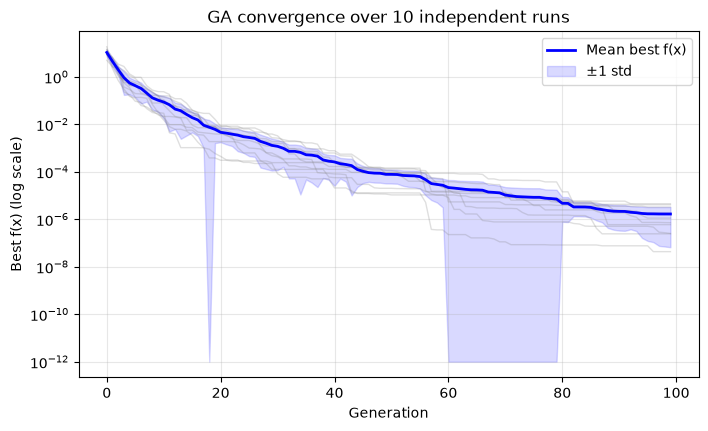

In [2]:
gens = np.arange(histories.shape[1])
mean = histories.mean(axis=0)
std = histories.std(axis=0)

plt.figure(figsize=(8, 4.5))
for h in histories:
    plt.plot(gens, h, color='grey', alpha=0.25, linewidth=1)
plt.plot(gens, mean, color='blue', linewidth=2, label='Mean best f(x)')
plt.fill_between(gens, np.maximum(mean - std, 1e-12), mean + std, color='blue', alpha=0.15, label='±1 std')
plt.yscale('log')
plt.xlabel('Generation'); plt.ylabel('Best f(x) (log scale)')
plt.title('GA convergence over 10 independent runs')
plt.legend(); plt.grid(True, alpha=0.3); plt.show()

### Convergence speed table

In [3]:
thresholds = [1.0, 0.1, 0.01]
for t in thresholds:
    reached = [np.argmax(h <= t) if np.any(h <= t) else None for h in histories]
    reached = [r for r in reached if r is not None]
    if reached:
        print(f"Reached f(x) <= {t:<5}: in {len(reached)}/{N_RUNS} runs, mean generation = {np.mean(reached):.1f}")
    else:
        print(f"Reached f(x) <= {t:<5}: never")

Reached f(x) <= 1.0  : in 10/10 runs, mean generation = 3.4
Reached f(x) <= 0.1  : in 10/10 runs, mean generation = 9.4
Reached f(x) <= 0.01 : in 10/10 runs, mean generation = 15.2


### Observation
- Every run's best value decreases over generations, and the mean curve shows a fast early drop followed by a slower refinement phase.
- The shaded band (±1 standard deviation) is narrow at the end, showing that independent runs converge to similar quality.
- The threshold table shows that tighter target values are reached at later generations, confirming diminishing returns.

### Conclusion
Ran the GA over multiple seeds, plotted mean and spread of convergence, and measured how many generations were needed to reach set accuracy thresholds.